In [2]:
# Siddhesh Mawale 23070521229
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)



Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


In [3]:
#normalize pixel value from 0-255 to 0-9
x_train = x_train
x_test = x_test

# add channel dimension
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

print(x_train.shape)
print(x_test.shape)



(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu', input_shape=(28,28,1)),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(120, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()



/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 120)            │       192,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,146 (828.70 KB)

 Trainable params: 212,146 (828.70 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)



Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 49s 56ms/step - accuracy: 0.9419 - loss: 0.3514 - val_accuracy: 0.9760 - val_loss: 0.0825
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 56ms/step - accuracy: 0.9821 - loss: 0.0594 - val_accuracy: 0.9837 - val_loss: 0.0607
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 55ms/step - accuracy: 0.9865 - loss: 0.0415 - val_accuracy: 0.9833 - val_loss: 0.0669
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 55ms/step - accuracy: 0.9896 - loss: 0.0319 - val_accuracy: 0.9853 - val_loss: 0.0653
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 55ms/step - accuracy: 0.9920 - loss: 0.0276 - val_accuracy: 0.9808 - val_loss: 0.0775


In [6]:
test_loss, accuracy_loss = model.evaluate(x_test,y_test)

print("Test Loss : ",test_loss)
print("Accuracy Loss: ",accuracy_loss)



313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9797 - loss: 0.0749
Test Loss :  0.07490354031324387
Accuracy Loss:  0.9797000288963318


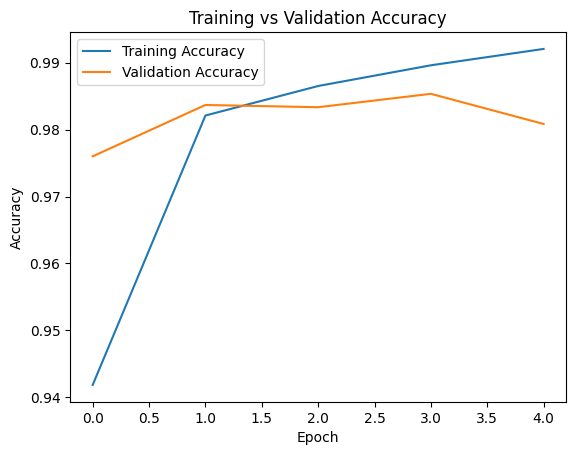

In [7]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.show()



In [8]:
predictions = model.predict(x_test)

predicted_digit = np.argmax(predictions[0])

print("Actual Digit:", y_test[0])
print("Predicted Digit:", predicted_digit)



313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Actual Digit: 7
Predicted Digit: 7


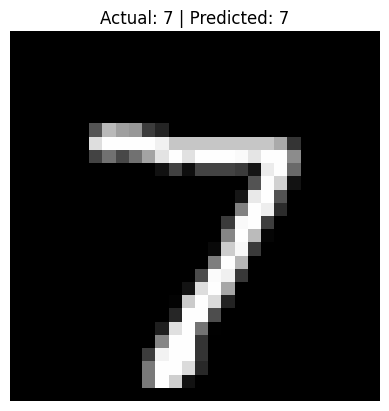

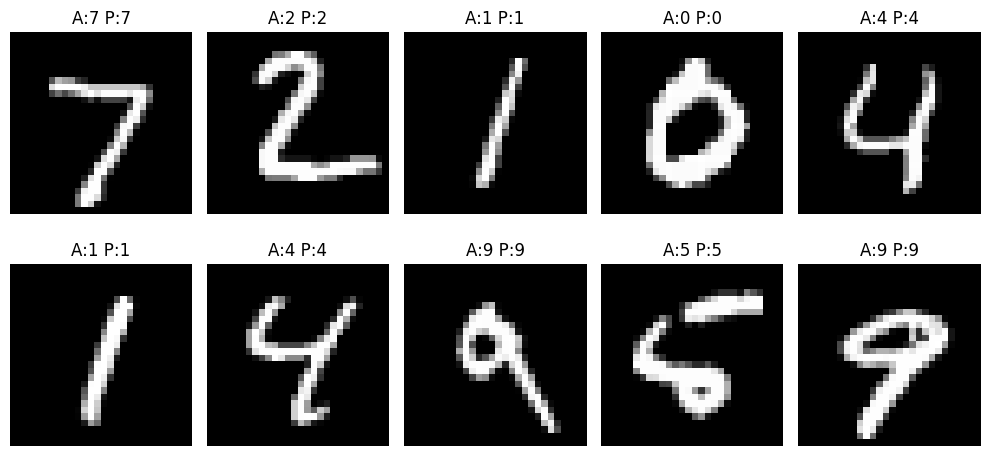

In [9]:
plt.imshow(x_test[0].reshape(28, 28), cmap='gray')
plt.title(f"Actual: {y_test[0]} | Predicted: {predicted_digit}")
plt.axis('off')
plt.show()

plt.figure(figsize=(10, 5))

for i in range(10):
    prediction = np.argmax(predictions[i])
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"A:{y_test[i]} P:{prediction}")
    plt.axis('off')

plt.tight_layout()
plt.show()